# CompBench Metrics Debug: Lowest-Scoring Samples

Load already-computed per-sample metrics and list the `TOP_N` weakest samples for each metric, including the input and annotation overlay, target/reference output, generated output, annotation details, and expandable agent trajectory. The replay section reproduces one sample's saved tool calls without asking the language model to plan again. Rankings are independent, so a sample may appear under multiple metrics. The default prompt mode is mixed; set `PROMPT_MODE` below or choose a run with `MMEDIT_COMPBENCH_TEXT_RUN` / `MMEDIT_COMPBENCH_MIXED_RUN`. The latest inference run is selected by default.

Worst direction: lower SSIM, PSNR, LC-T, and LC-I; higher LPIPS. Optionally set `TASK_FILTER` to a task name such as `multi_object_add`, or leave it `None` to include all tasks. Replay is split into preparation, model loading, and Act execution cells; only the model-loading cell initializes inference models.

In [1]:
import os
from pathlib import Path

from evaluation.notebook import load_benchmark, resolve_run_directory

PROMPT_MODE = "mixed"  # "mixed" or "text"
TOP_N = 10
TASK_FILTER = None  # Example: "multi_object_add"

context = load_benchmark("compbench", prompt_mode=PROMPT_MODE)
run_env = f"MMEDIT_COMPBENCH_{PROMPT_MODE.upper()}_RUN"
OUTPUT_DIR = resolve_run_directory(
    context.output_dir, os.environ.get(run_env) or None
)
METRICS_PATH = OUTPUT_DIR / "metrics" / "compbench_metrics.jsonl"
RESULTS_PATH = OUTPUT_DIR / "results" / "results.jsonl"
print("Annotations:", context.annotation_file)
print("Inference run:", OUTPUT_DIR)
print("Metric rows:", METRICS_PATH)
print("Top N:", TOP_N, "| task filter:", TASK_FILTER or "all")

Annotations: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/annotation/compbench/run_20261007_000000_000000/compbench_local_multiobject_mixed.jsonl
Inference run: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/evaluation/compbench/mixed/run_20261011_214946_086189
Metric rows: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/evaluation/compbench/mixed/run_20261011_214946_086189/metrics/compbench_metrics.jsonl
Top N: 10 | task filter: all


Rank,SSIM,Task,Sample ID,Original instruction,Mixed instruction,Files
1,0.6610,multi_object_remove,multi_object_remove:1dc12eca_00042.png,remove the grey bird on the right and the yellow bird in the middle,remove <v1> and <v2> and the yellow bird in the middle,output
2,0.6696,replace,replace:a5905593/0/00068.png,replace the red large bus with a half-exposed tree full of red leaves,replace <v1> with a half-exposed tree full of red leaves,output
3,0.7094,add,add:80fb79c6/0/00093.png,"add a tiger with similar fur on the right side of the stairs, lying on its side with its head facing right","add a tiger with similar fur at <v1>, lying on its side with its head facing right",output
4,0.7132,replace,replace:f494e9fa/0/00002.png,replace the grey-black dog with a silver-blue chair,replace <v1> with a silver-blue chair,output
5,0.7156,replace,replace:e7529cbc/0/00008.png,replace the bus with a white van driving to the left,replace <v1> with a white van driving to the left,output
6,0.7303,add,add:199995b5/3/00028.png,"add a giraffe on the left side of the first giraffe from the rightmost with similar color, heading right and with its back to the viewer","add a giraffe at <v1> with similar color, heading right and with its back to the viewer",output
7,0.7322,add,add:fbfb6e30/1/00019.png,"add a man on the right side of the child who is wearing glasses, wearing a hooded coat, and raising his left hand","add a man at <v1> who is wearing glasses, wearing a hooded coat, and raising his left hand",output
8,0.7422,multi_object_remove,multi_object_remove:a92390a0_00030.png,remove the sheep in front and the third sheep from front,remove <v1> and <v2>,output
9,0.7428,replace,replace:f494e9fa/0/00009.png,replace the greyhound with a bench,replace <v1> with a bench,output
10,0.7451,add,add:994ed763/0/00043.png,"add a white duck on the lower right with its head facing right, showing only the upper part of its body","add a white duck at <v1> with its head facing right, showing only the upper part of its body",output



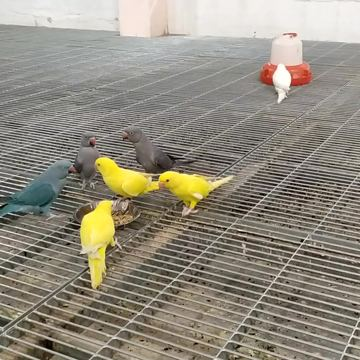
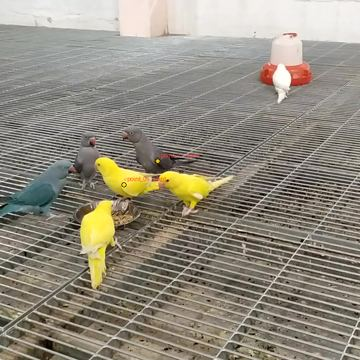
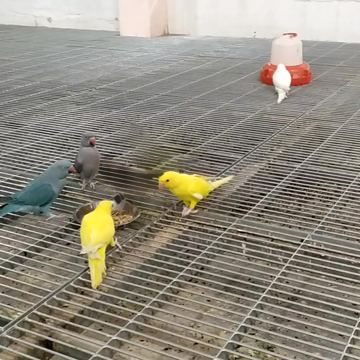
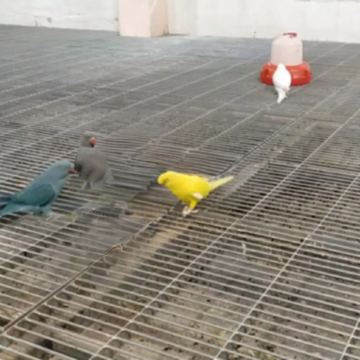


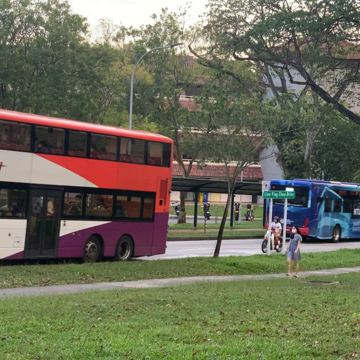
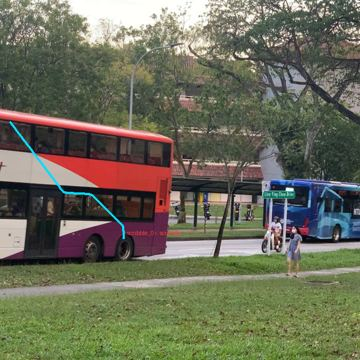
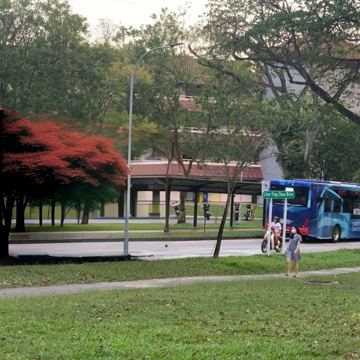
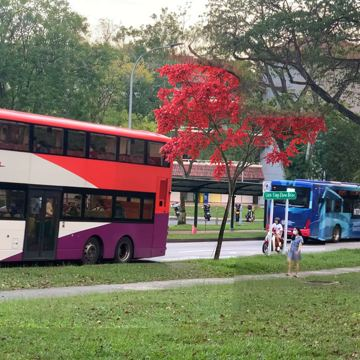


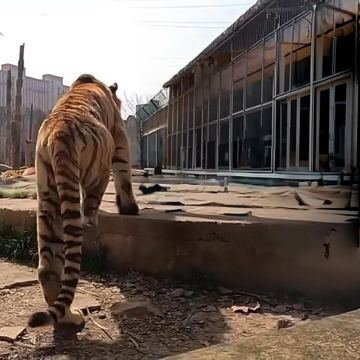
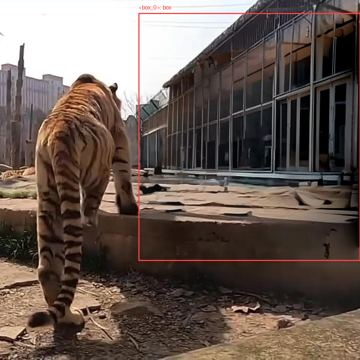
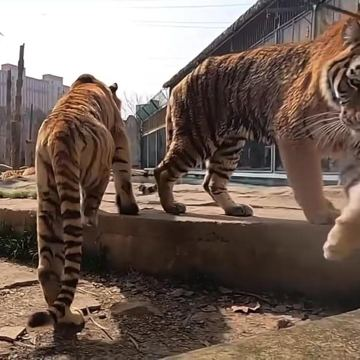
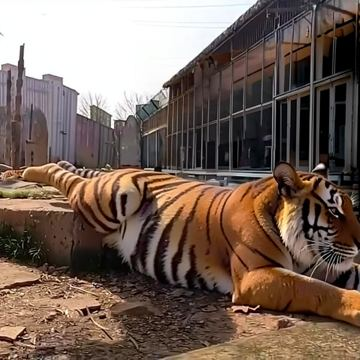


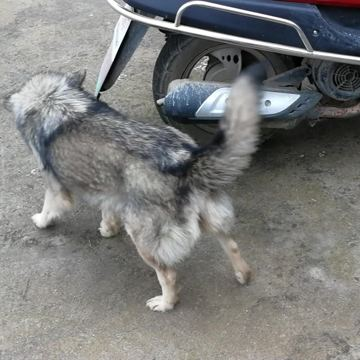
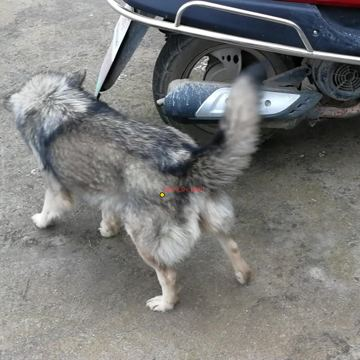
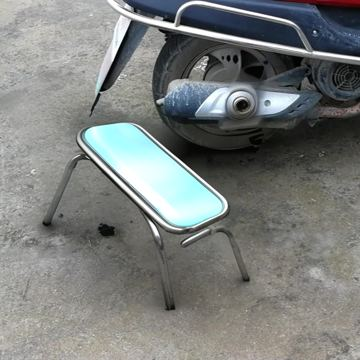
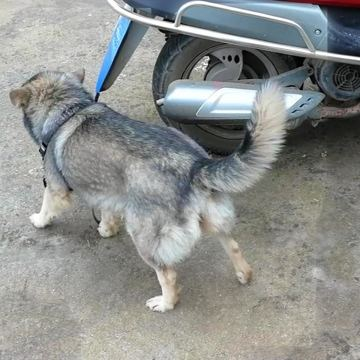


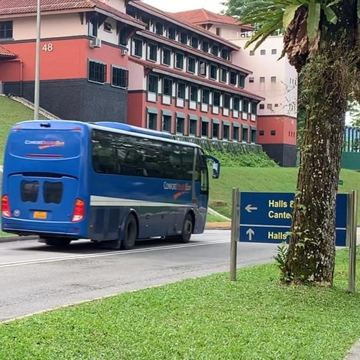
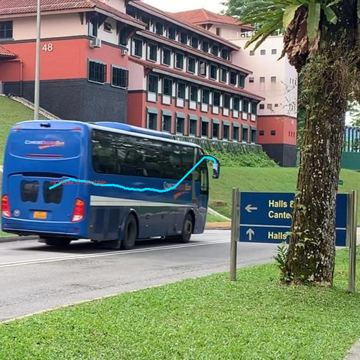
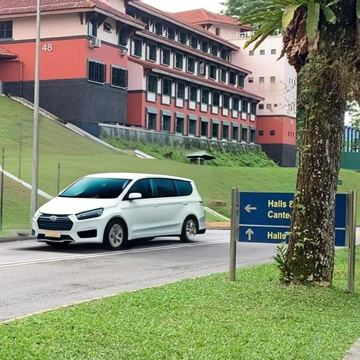
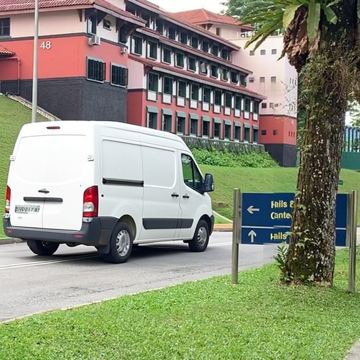


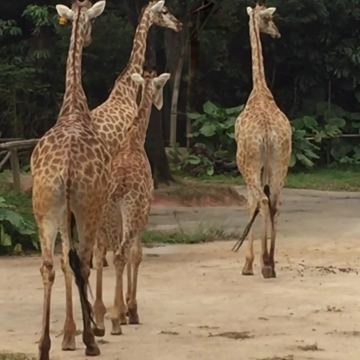
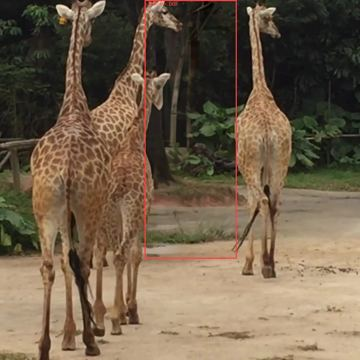
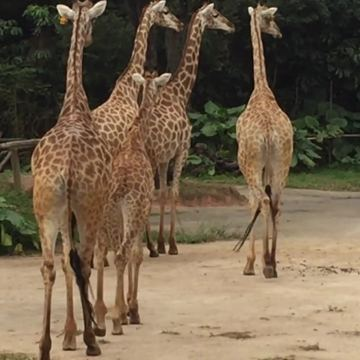
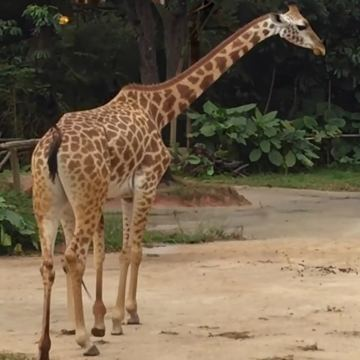


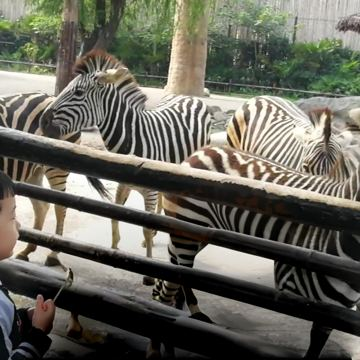
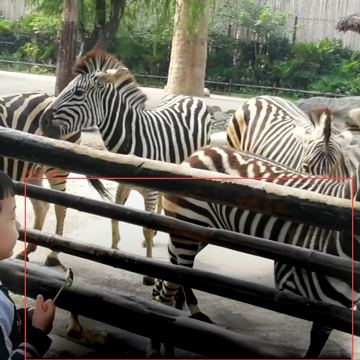
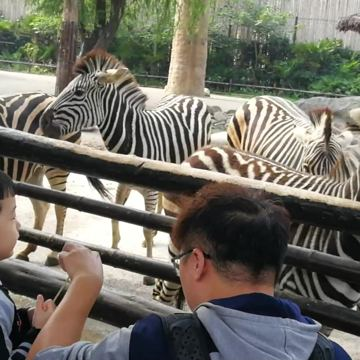
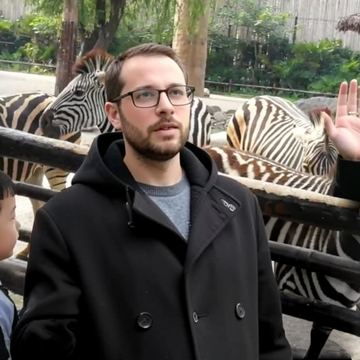


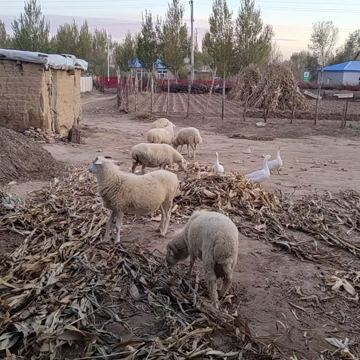
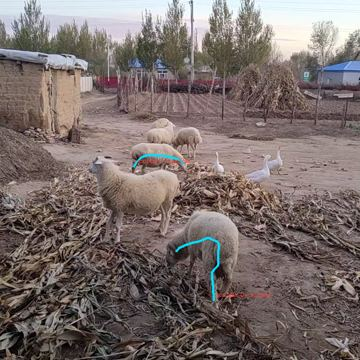
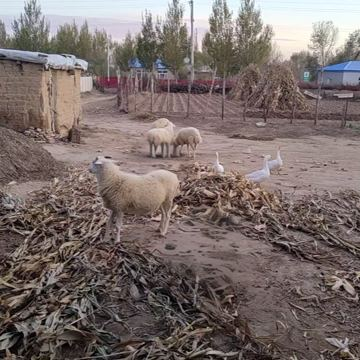
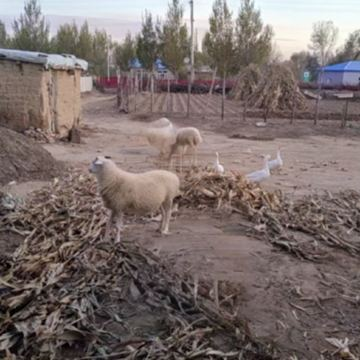


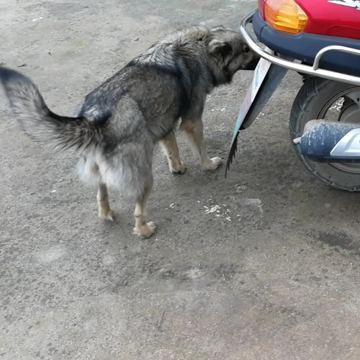
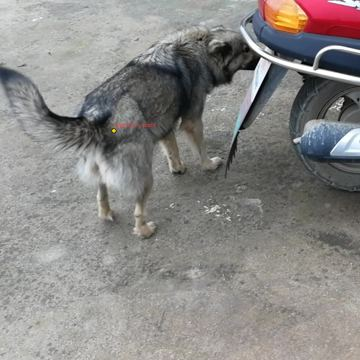
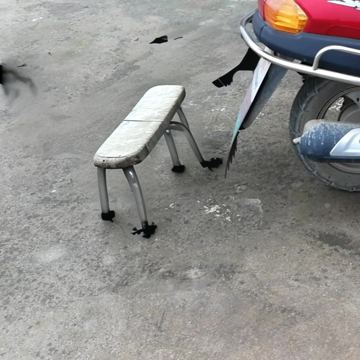
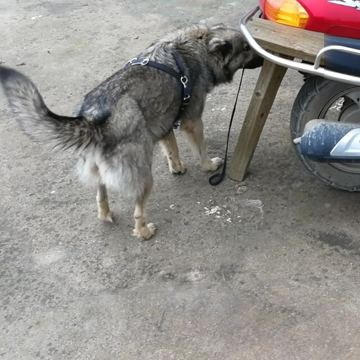


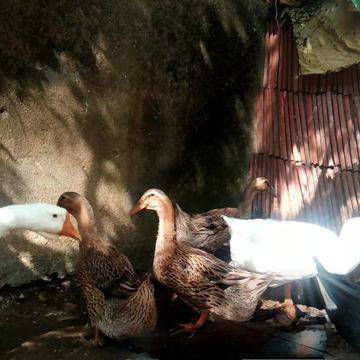
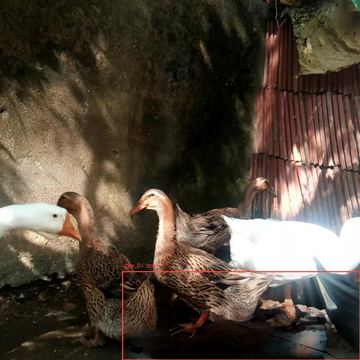
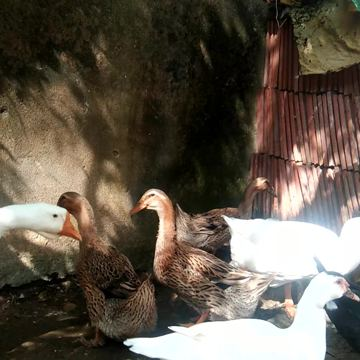
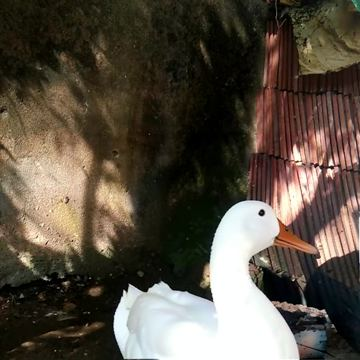

Rank,PSNR,Task,Sample ID,Original instruction,Mixed instruction,Files
1,11.9519,add,add:994ed763/0/00043.png,"add a white duck on the lower right with its head facing right, showing only the upper part of its body","add a white duck at <v1> with its head facing right, showing only the upper part of its body",output
2,12.1519,add,add:0b27d5f7/1/00002.png,add a short-haired slightly fat man wearing a white T-shirt and glasses standing in front of the feeding trough,add a short-haired slightly fat man wearing a white T-shirt and glasses standing at <v1>,output
3,12.3402,multi_object_add,multi_object_add:1dc0c9a0_00016.png,add a big sea turtle and add a smaller one on the bottom right of it,add <v1> and add a smaller one at <v2>,output
4,13.1653,add,add:fbfb6e30/1/00019.png,"add a man on the right side of the child who is wearing glasses, wearing a hooded coat, and raising his left hand","add a man at <v1> who is wearing glasses, wearing a hooded coat, and raising his left hand",output
5,14.0800,add,add:994ed763/0/00040.png,"add a white duck on the lower side of the brown duck below the flock of ducks, with its head facing right","add a white duck at <v1>, with its head facing right",output
6,14.5438,add,add:0b27d5f7/1/00004.png,"add a short-haired, slightly fat man wearing a white T-shirt and glasses standing in front of the feeding trough","add a short-haired, slightly fat man wearing a white T-shirt and glasses standing at <v1>",output
7,14.9290,add,add:5ba84e3f/0/00071.png,add a yellow dog on the leftmost with its back facing and showing its butt,add a yellow dog on <v1> with its back facing and showing its butt,output
8,15.1118,add,add:2ea465de/0/00197.png,add a man wearing a blue-black cotton coat on the lower side going up the steps,add a man wearing a blue-black cotton coat at <v1>,output
9,15.3253,add,add:b33ade7c/2/00057.png,"add a zebra on the right side of the group of zebras, with its back facing and side body towards the left","add a zebra at <v1>, with its back facing and side body towards the left",output
10,15.3446,add,add:fbfb6e30/1/00023.png,"add a man on the right side of the child, who is wearing a sweater and glasses","add a man at <v1>, who is wearing a sweater and glasses",output



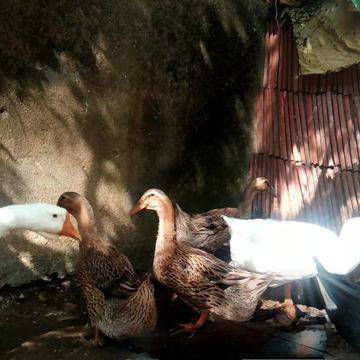
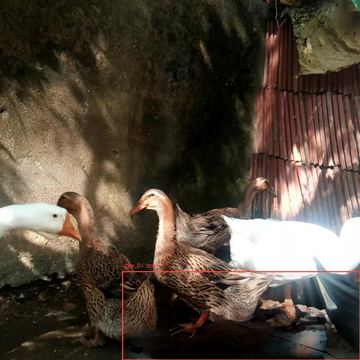
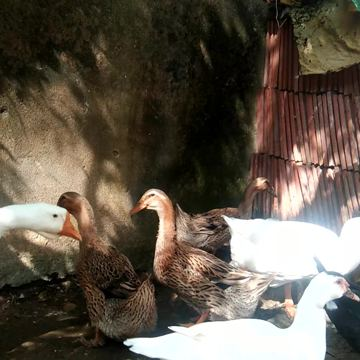
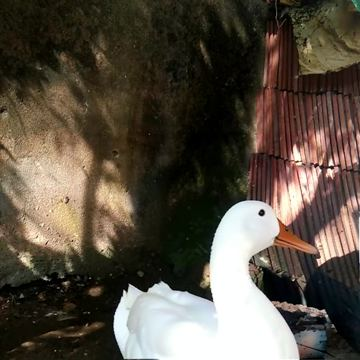


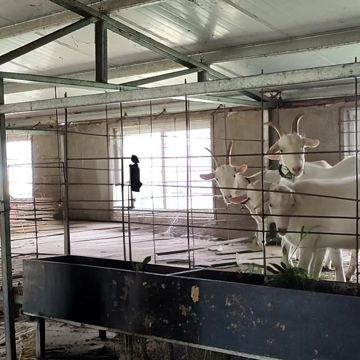
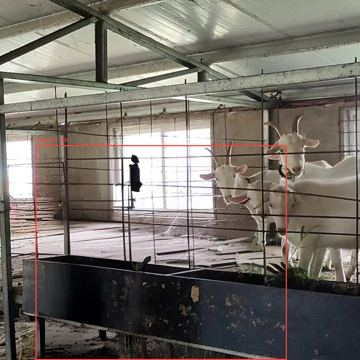
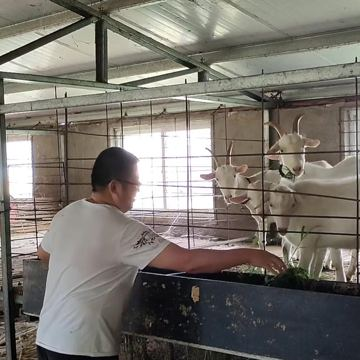
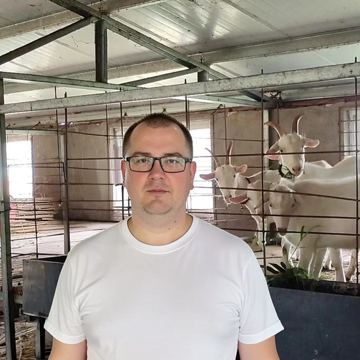


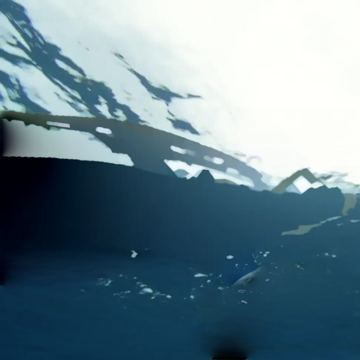
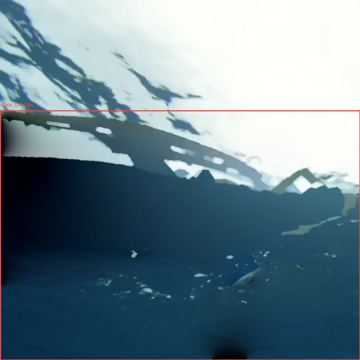
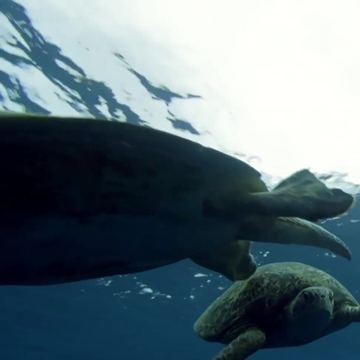
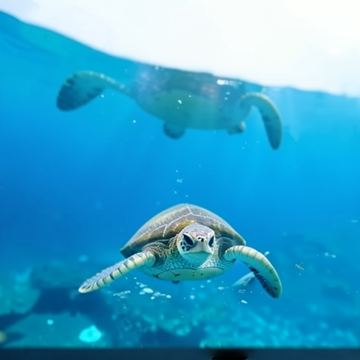


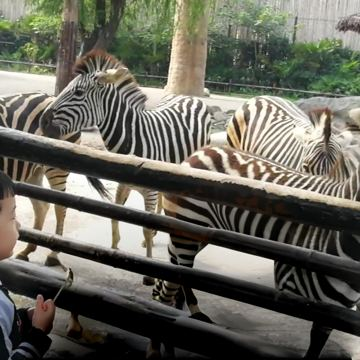
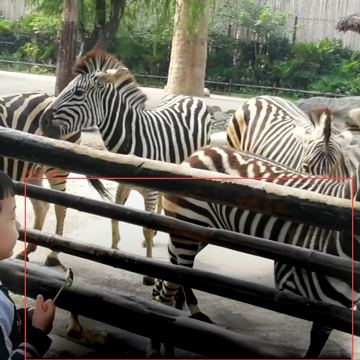
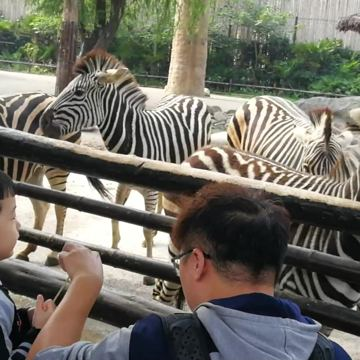
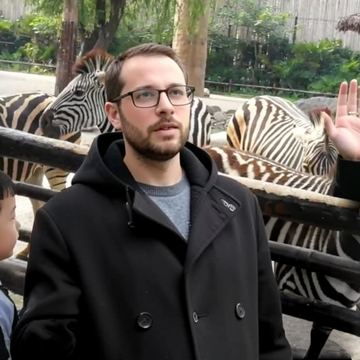


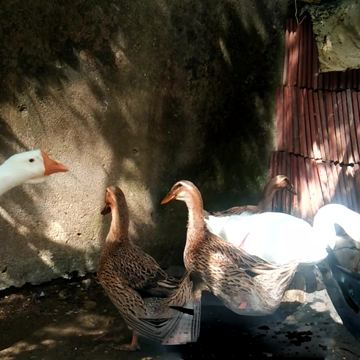
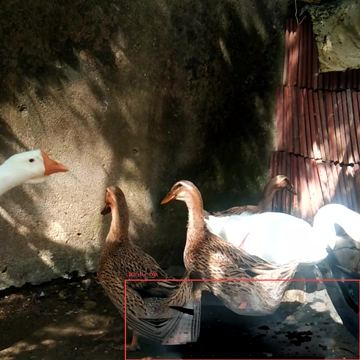
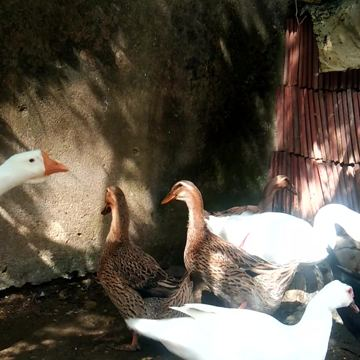
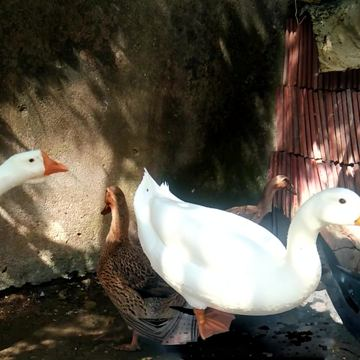


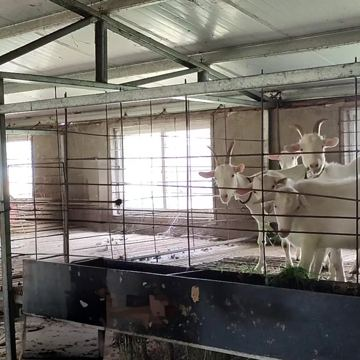
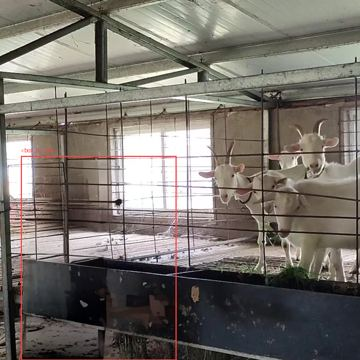
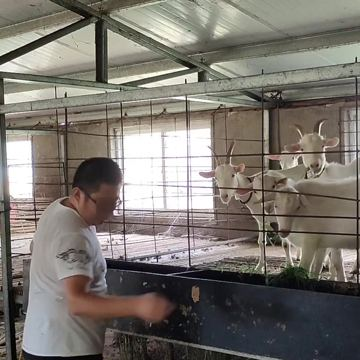
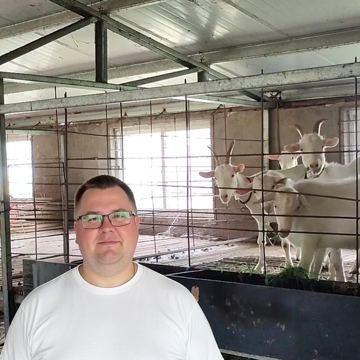


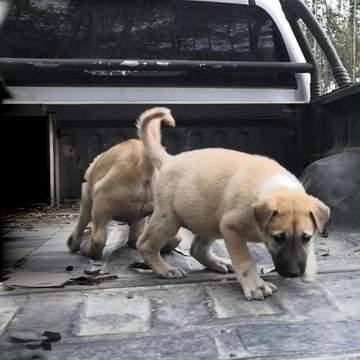
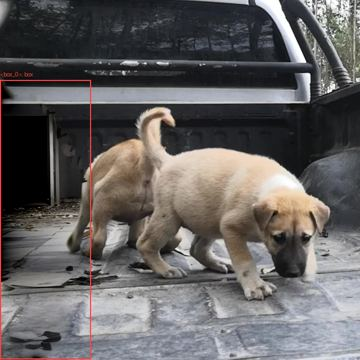
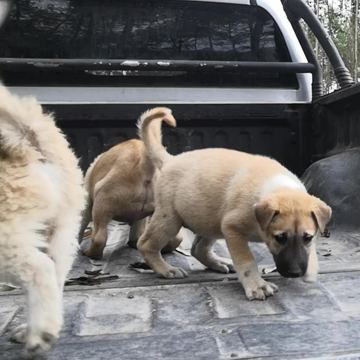
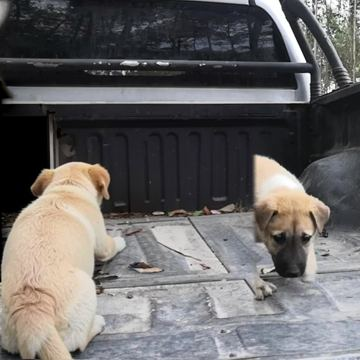


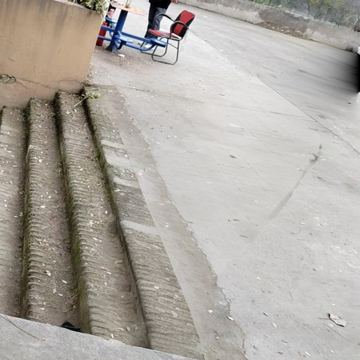
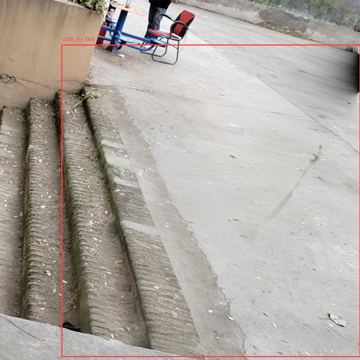
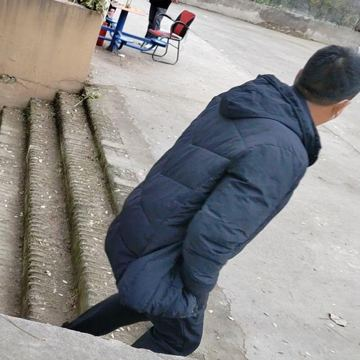
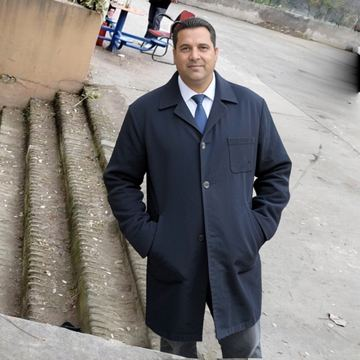


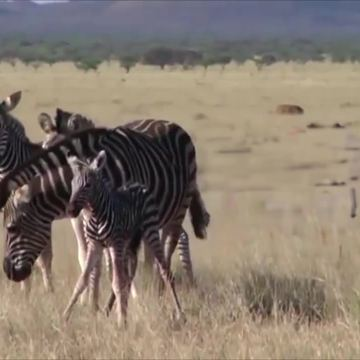
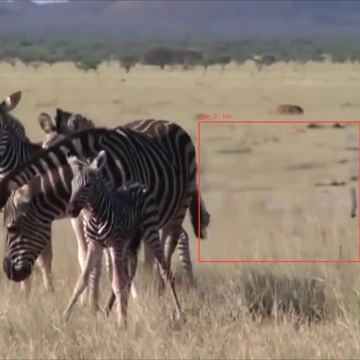
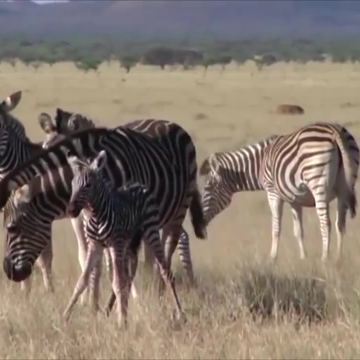
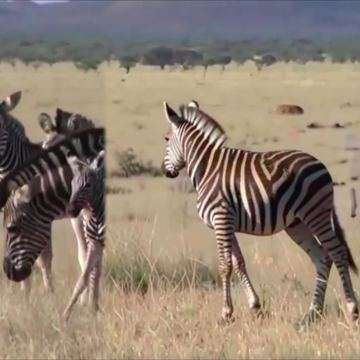


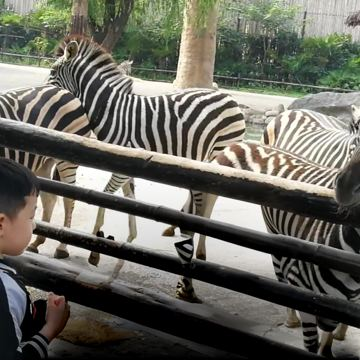
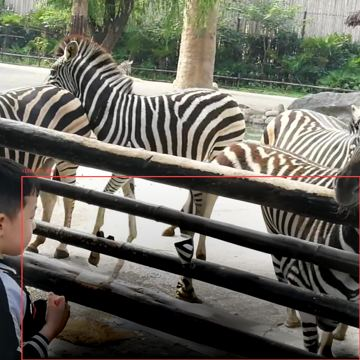
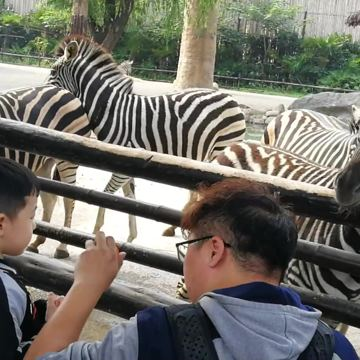
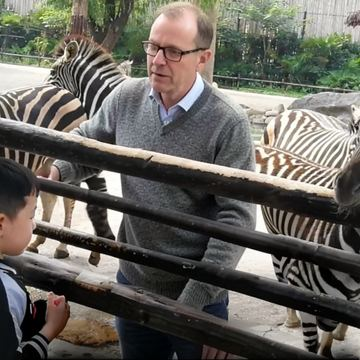

Rank,LPIPS,Task,Sample ID,Original instruction,Mixed instruction,Files
1,0.2100,add,add:80fb79c6/0/00093.png,"add a tiger with similar fur on the right side of the stairs, lying on its side with its head facing right","add a tiger with similar fur at <v1>, lying on its side with its head facing right",output
2,0.2098,multi_object_remove,multi_object_remove:1dc12eca_00042.png,remove the grey bird on the right and the yellow bird in the middle,remove <v1> and <v2> and the yellow bird in the middle,output
3,0.2046,add,add:994ed763/0/00043.png,"add a white duck on the lower right with its head facing right, showing only the upper part of its body","add a white duck at <v1> with its head facing right, showing only the upper part of its body",output
4,0.2014,multi_object_add,multi_object_add:1dc0c9a0_00016.png,add a big sea turtle and add a smaller one on the bottom right of it,add <v1> and add a smaller one at <v2>,output
5,0.1902,multi_object_remove,multi_object_remove:a92390a0_00030.png,remove the sheep in front and the third sheep from front,remove <v1> and <v2>,output
6,0.1853,multi_object_remove,multi_object_remove:a92390a0_00043.png,remove the leftmost sheep and the black duck in the bottom right corner,remove <v1> and <v2>,output
7,0.1848,add,add:fbfb6e30/1/00019.png,"add a man on the right side of the child who is wearing glasses, wearing a hooded coat, and raising his left hand","add a man at <v1> who is wearing glasses, wearing a hooded coat, and raising his left hand",output
8,0.1799,remove,remove:337dfa1e/0/00115.png,remove the person on the ground and tree,remove <v1> and tree,output
9,0.1758,remove,remove:337dfa1e/0/00105.png,remove the person on the ground and building exterior,remove <v1> and building exterior,output
10,0.1727,add,add:199995b5/3/00028.png,"add a giraffe on the left side of the first giraffe from the rightmost with similar color, heading right and with its back to the viewer","add a giraffe at <v1> with similar color, heading right and with its back to the viewer",output



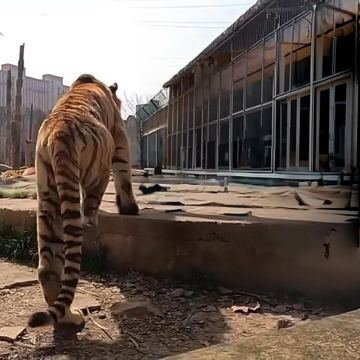
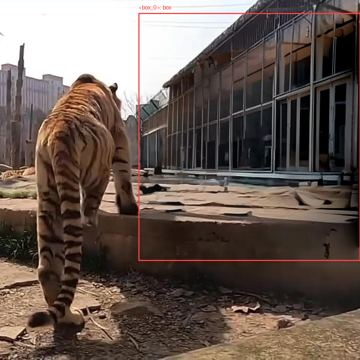
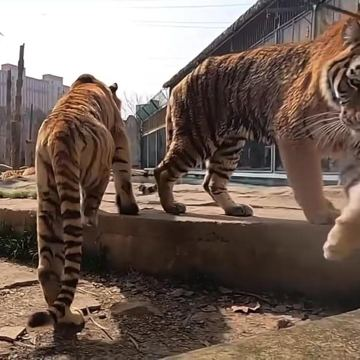
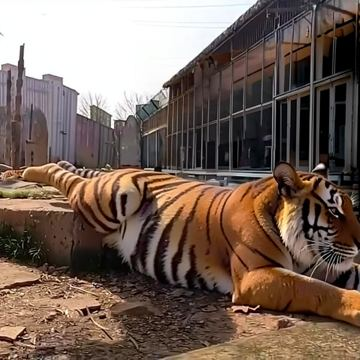


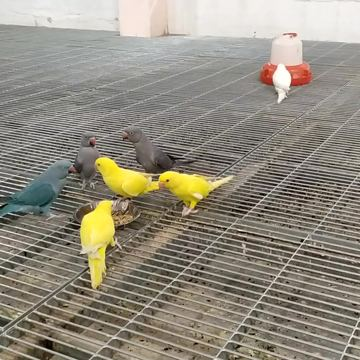
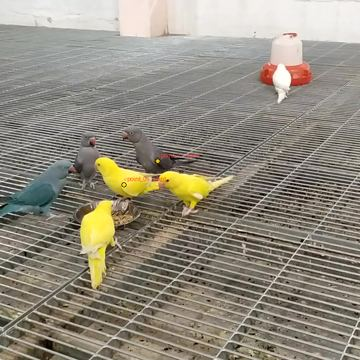
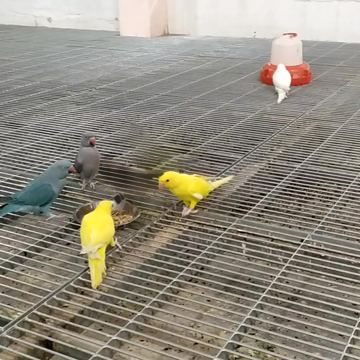
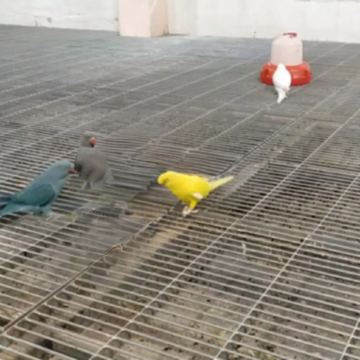


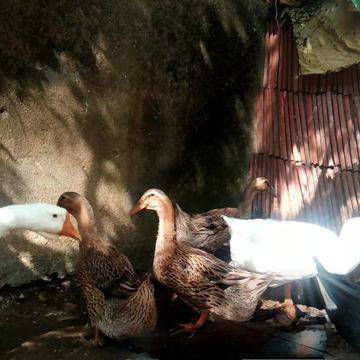
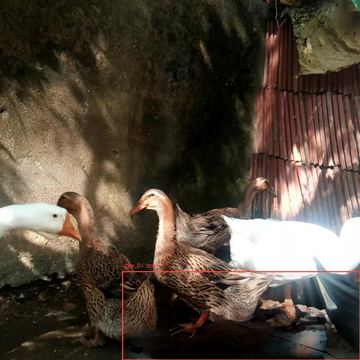
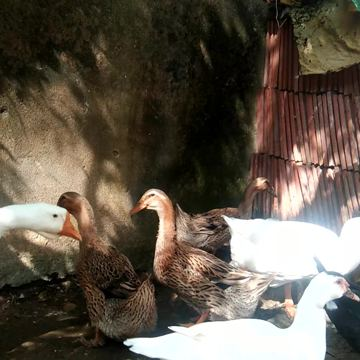
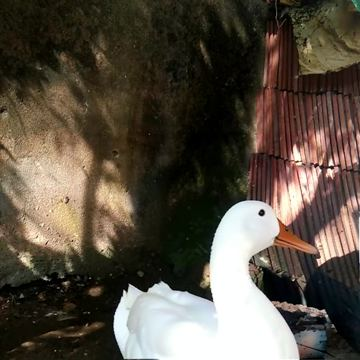


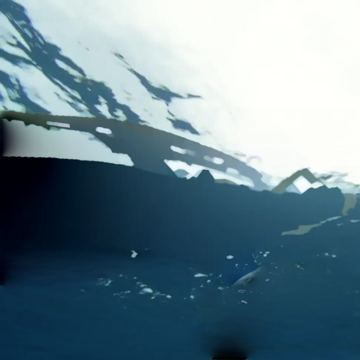
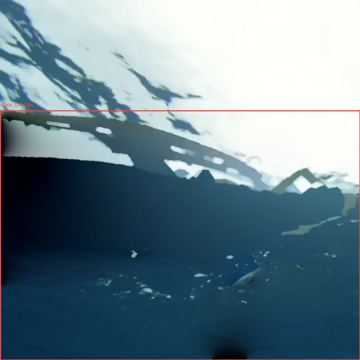
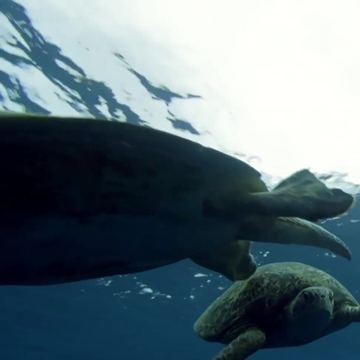
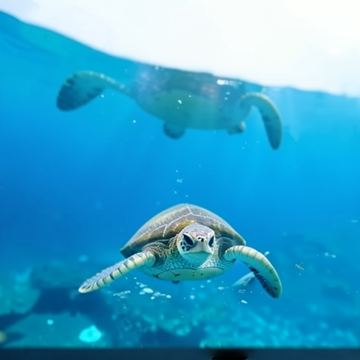


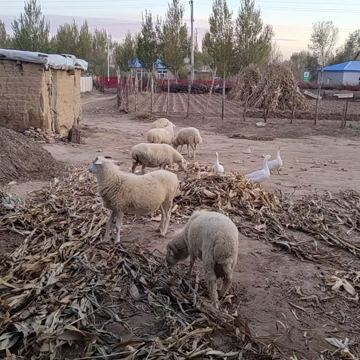
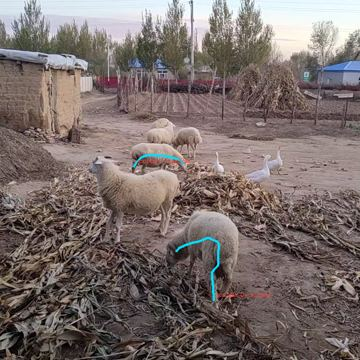
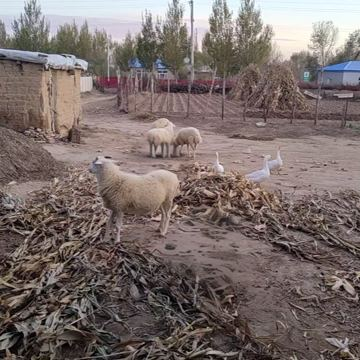
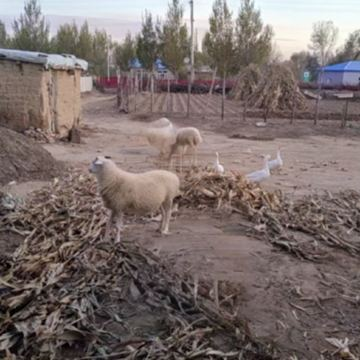


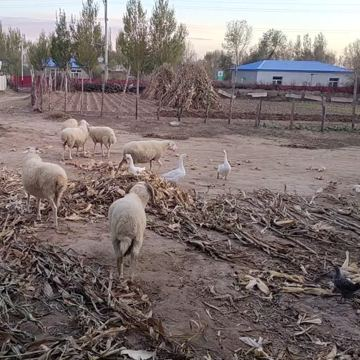
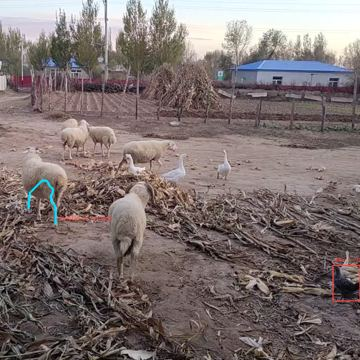
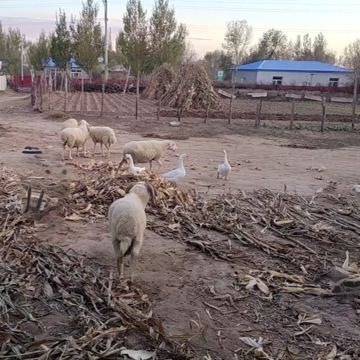
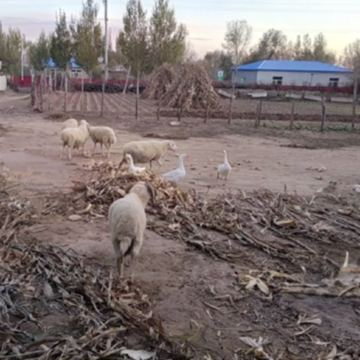


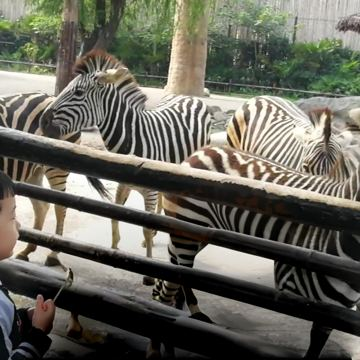
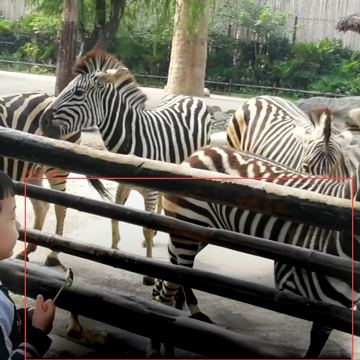
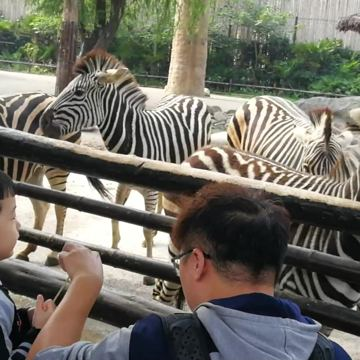
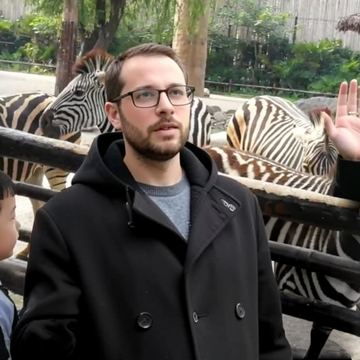


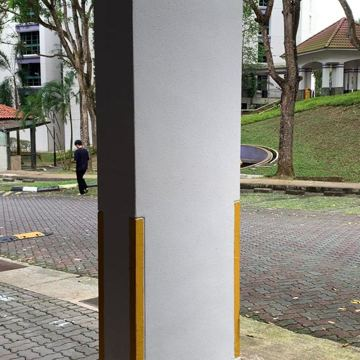
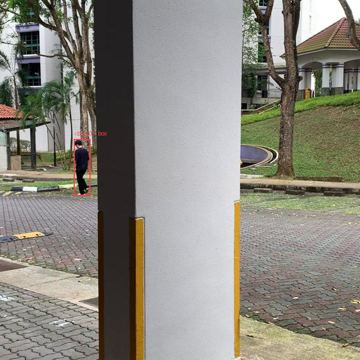
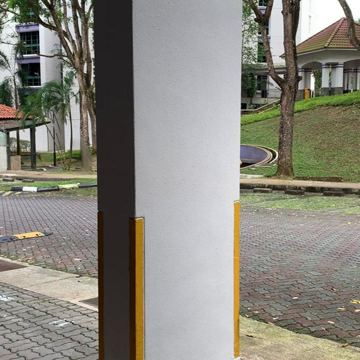
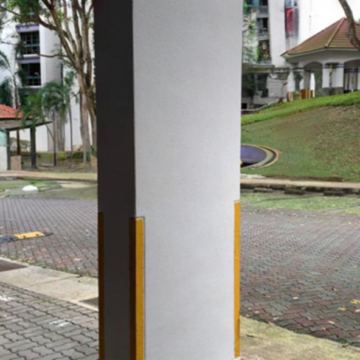


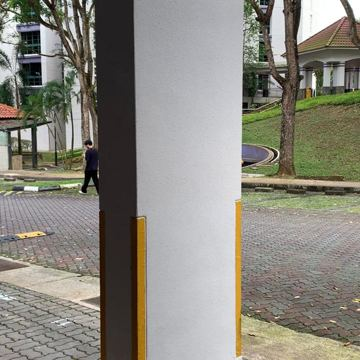
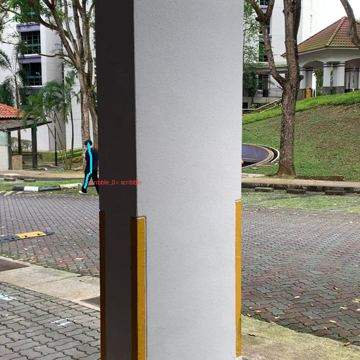
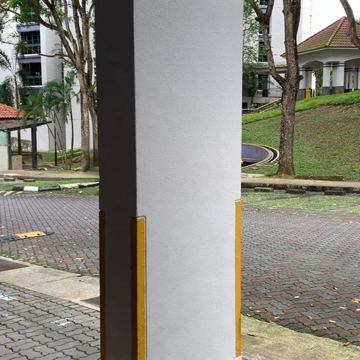
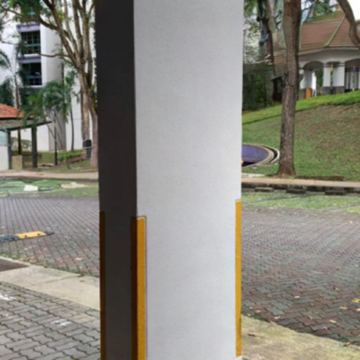


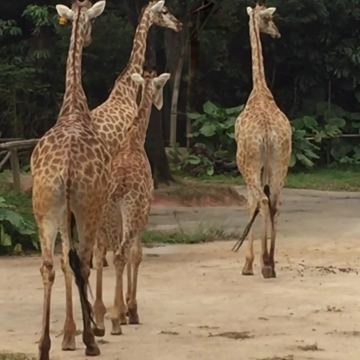
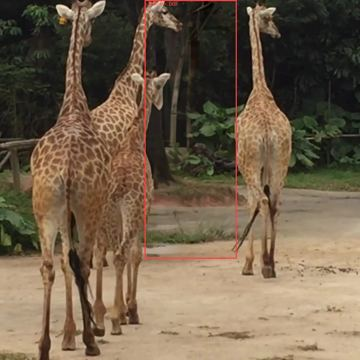
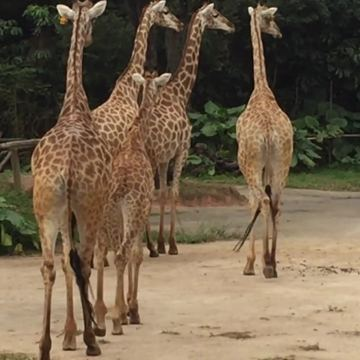
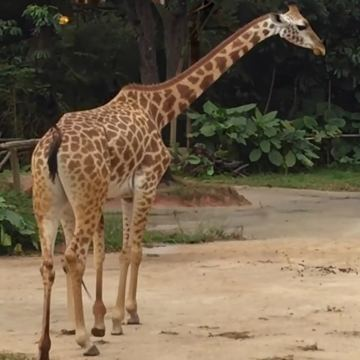

Rank,LC-T,Task,Sample ID,Original instruction,Mixed instruction,Files
1,9.3954,replace,replace:405c6000/1/00000.png,replace the giraffe with a black bird facing left,replace <v1> with a black bird facing left,output
2,10.2160,add,add:6dff20c9/0/00008.png,"add a white goose with an orange beak stretching its neck, located in the lower left corner and showing only half of its body","add a white goose with an orange beak stretching its neck, located in <v1> and showing only half of its body",output
3,10.2520,remove,remove:a38d648a/0/00039.png,remove the rabbit on the upper side,remove <v1>,output
4,10.7369,multi_object_remove,multi_object_remove:843d8f25_00046.png,remove the zebra hunted by the lion and the second zebra on the right,remove <v1> and <v2>,output
5,10.7744,replace,replace:5d2316f6/0/00013.png,replace the bottommost sheep with a bench,replace <v1> with a bench,output
6,10.9758,remove,remove:9b5f0f47/1/00040.png,remove the light yellow fish,remove <v1>,output
7,11.3145,remove,remove:8d0d641a/0/00042.png,remove the second black duck on the left,remove <v1>,output
8,11.3859,replace,replace:d2abc61e/1/00019.png,replace the dog on the left with a chair,replace <v1> with a chair,output
9,11.4843,multi_object_remove,multi_object_remove:54273925_00004.png,remove the two sheep,remove <v1> and <v2>,output
10,11.5503,replace,replace:9d5940d2/1/00029.png,replace the turtle on the right with a black small table,replace <v1> with a black small table,output



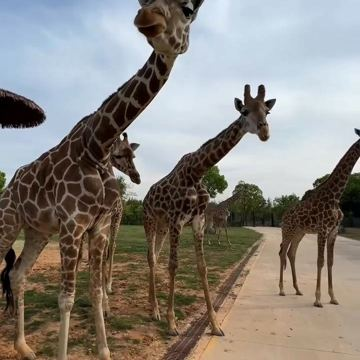
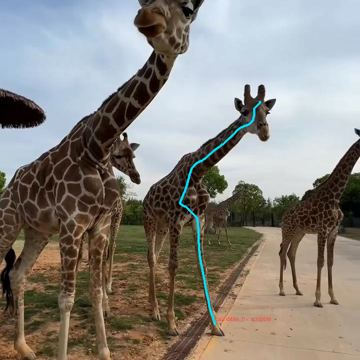
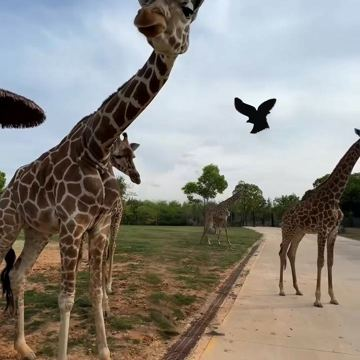
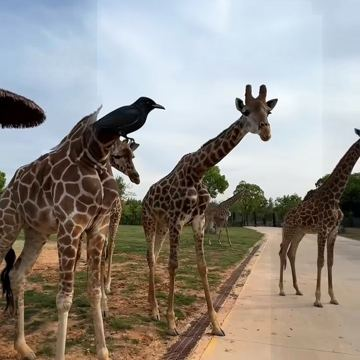


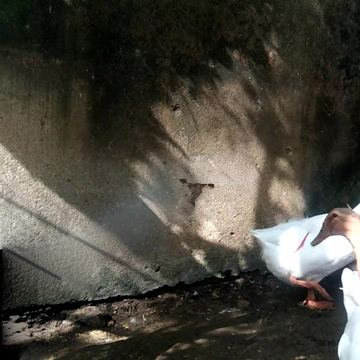
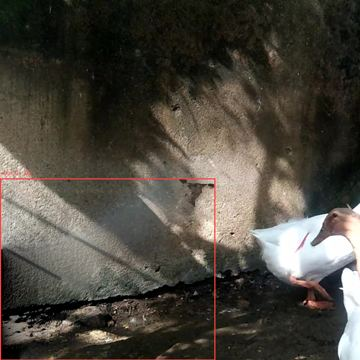
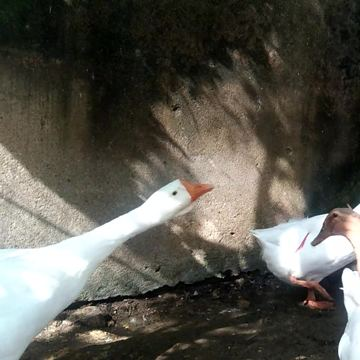
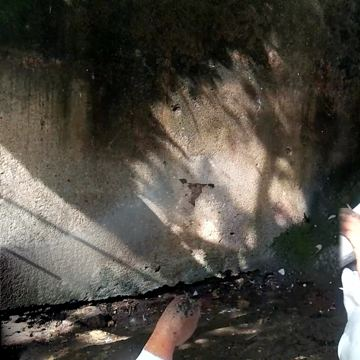


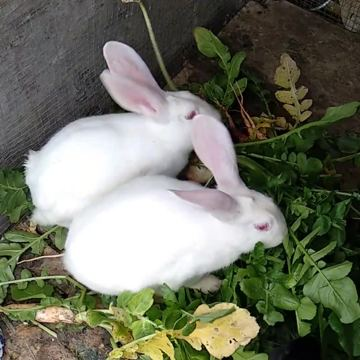
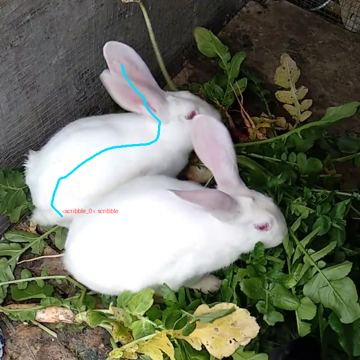
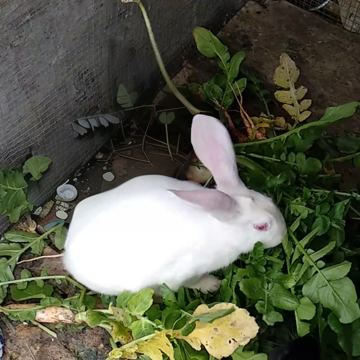
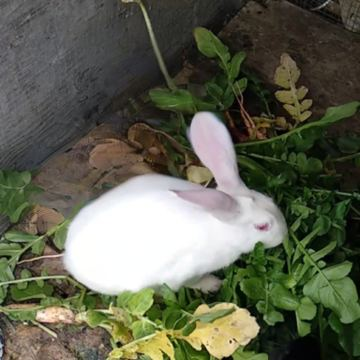


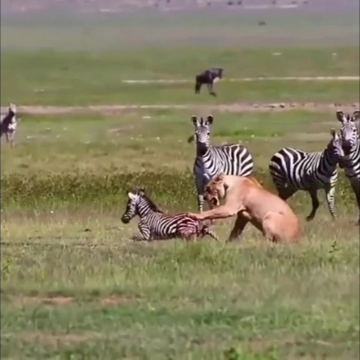
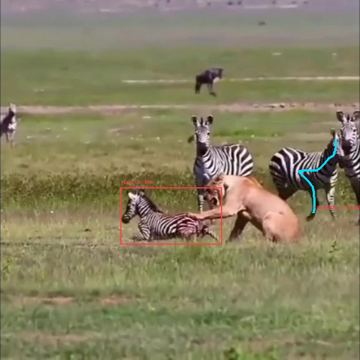
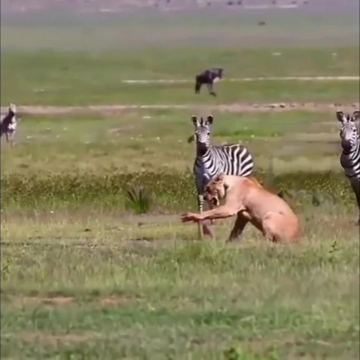
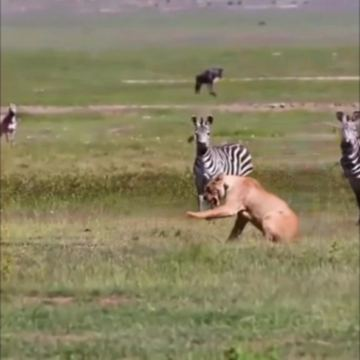


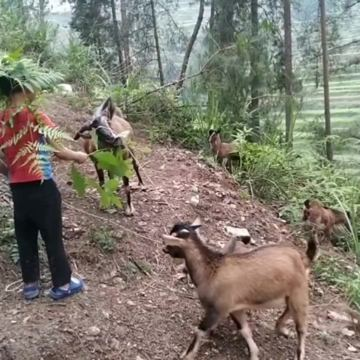
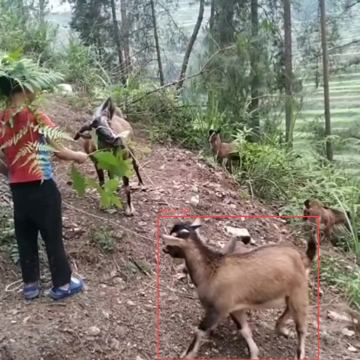
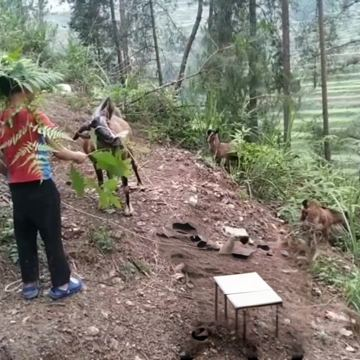
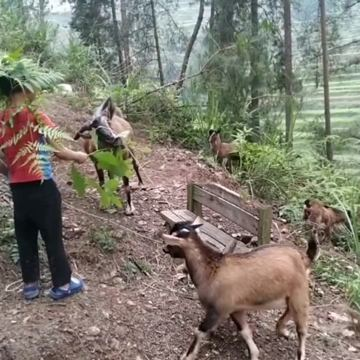


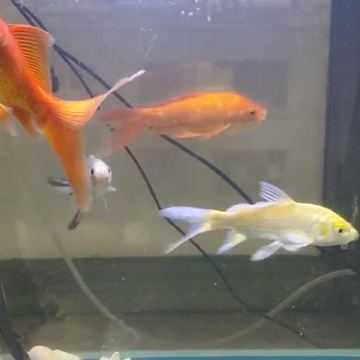
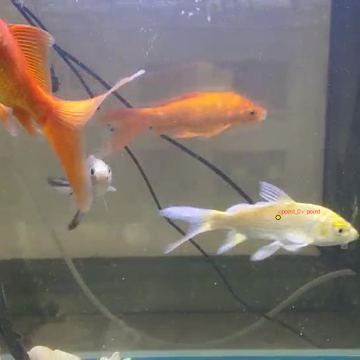
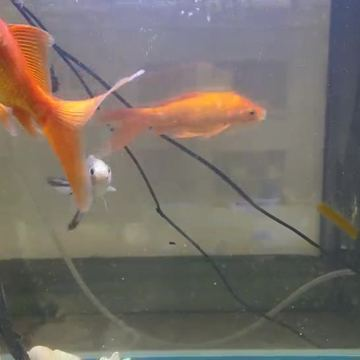
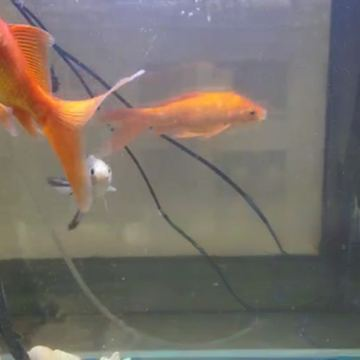


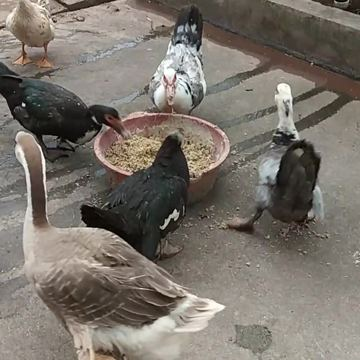
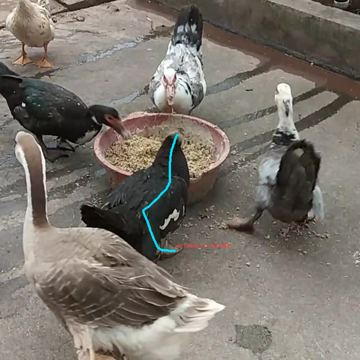
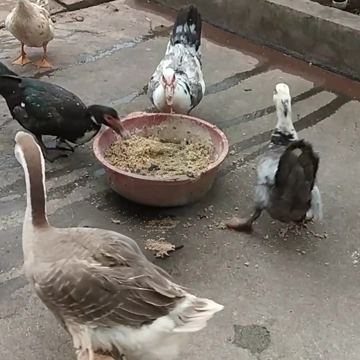
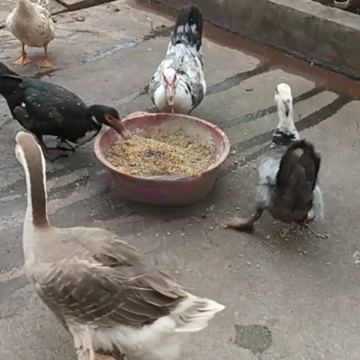


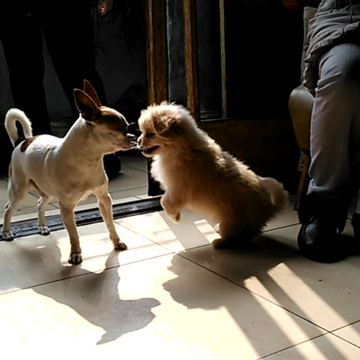
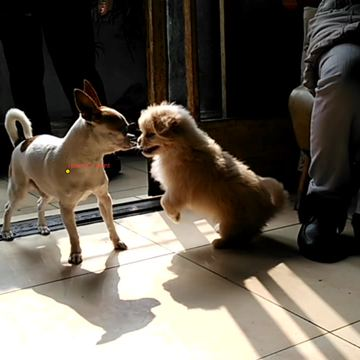
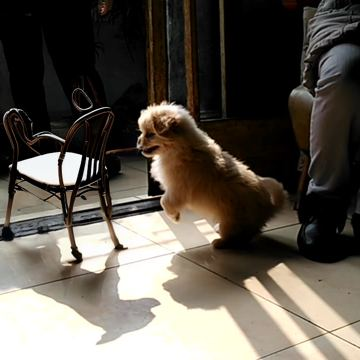
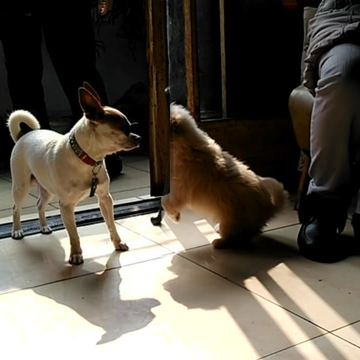


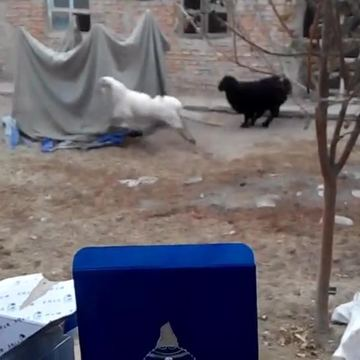
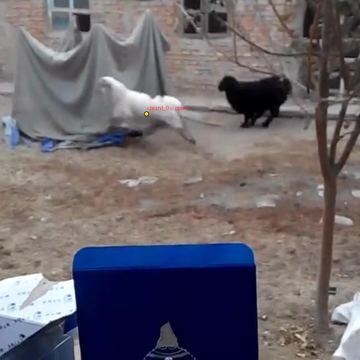
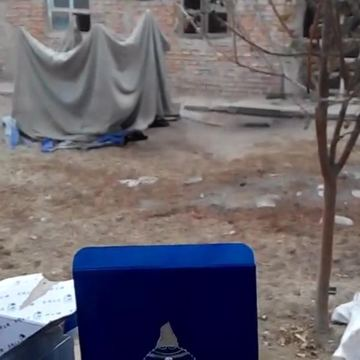
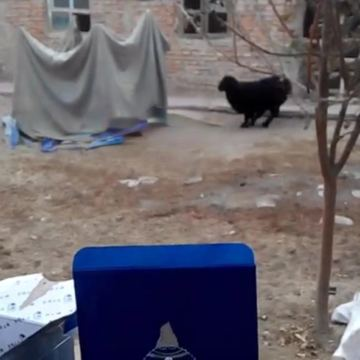


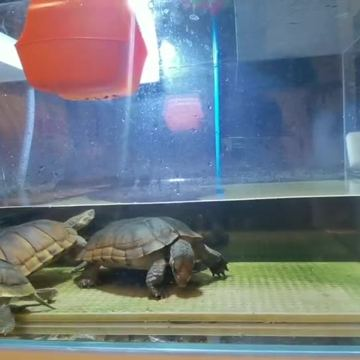
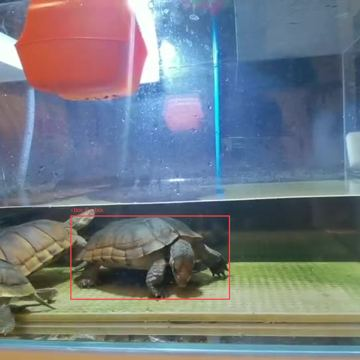
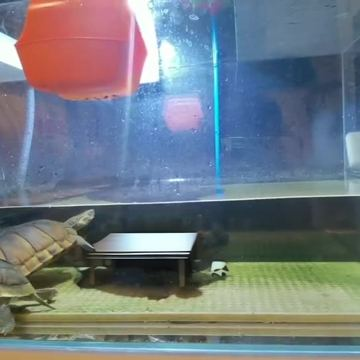
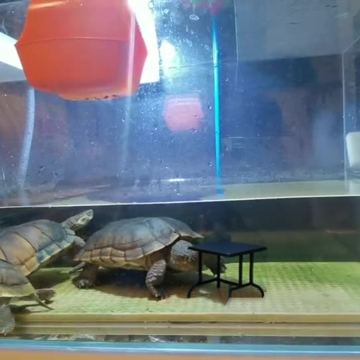

Rank,LC-I,Task,Sample ID,Original instruction,Mixed instruction,Files
1,0.5452,replace,replace:de2f2a6a/2/00142.png,replace the white chicken with a white sign,replace <v1> with a white sign,output
2,0.5782,add,add:001ca3cb/0/00027.png,add a pink and white fish on the leftmost heading to the lower right,add a pink and white fish at <v1> heading to the lower right,output
3,0.5845,replace,replace:6a6e0e3b/4/00003.png,replace the cat in the lower right with a black pot lid,replace <v1> with a black pot lid,output
4,0.5947,replace,replace:89b671bb/4/00010.png,replace the car on the right with a white car facing left,replace <v1> with a white car facing left,output
5,0.6007,replace,replace:86571569/1/00009.png,replace the leftmost rabbit with a small table model,replace <v1> with a small table model,output
6,0.6016,replace,replace:d869a3cf/0/00052.png,replace the white sheep in front with a black chair,replace <v1> with a black chair,output
7,0.6083,add,add:fbfb6e30/1/00021.png,"add a man on the right side of the child with his left hand raised, wearing a gray-blue sweater and glasses","add a man at <v1> with his left hand raised, wearing a gray-blue sweater and glasses",output
8,0.6089,replace,replace:5d2316f6/0/00013.png,replace the bottommost sheep with a bench,replace <v1> with a bench,output
9,0.6141,replace,replace:beb693c9/0/00001.png,replace the boat below with a bridge,replace <v1> with a bridge,output
10,0.6159,add,add:ba9ea03d/0/00175.png,add a white dog on the right near the white cloth,add a white dog at <v1>,output



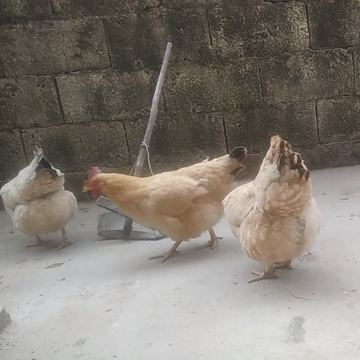
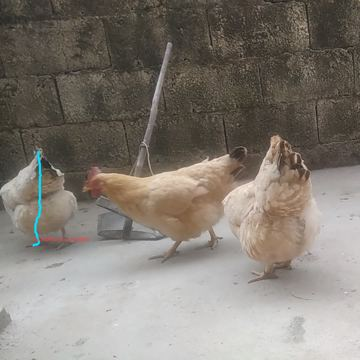
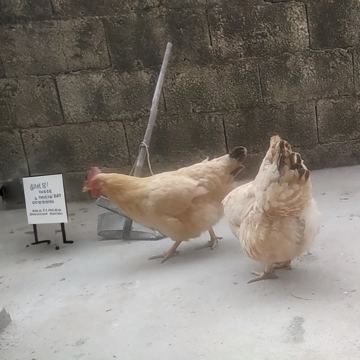
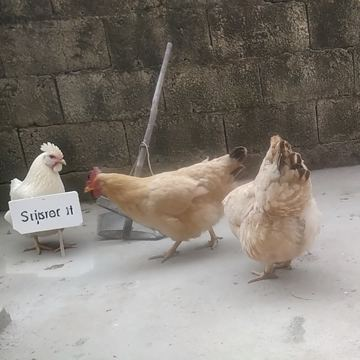


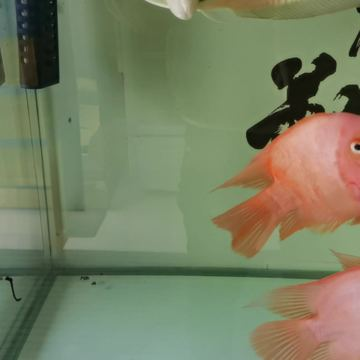
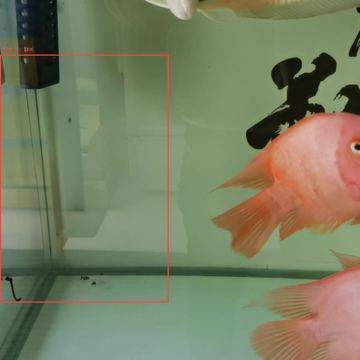
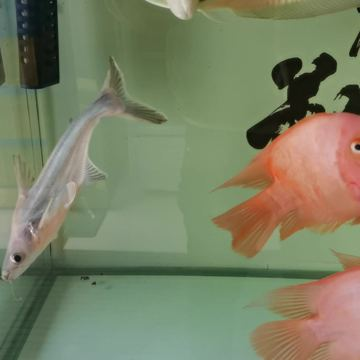
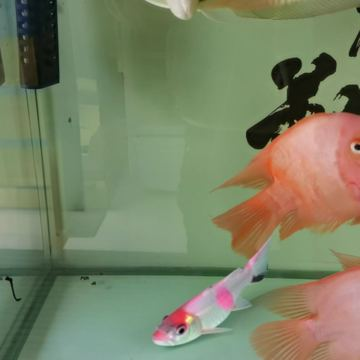


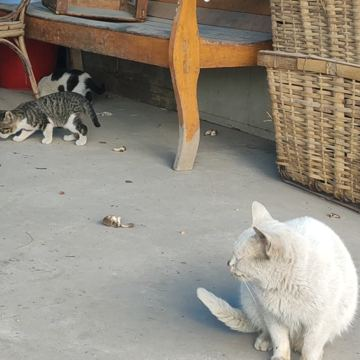
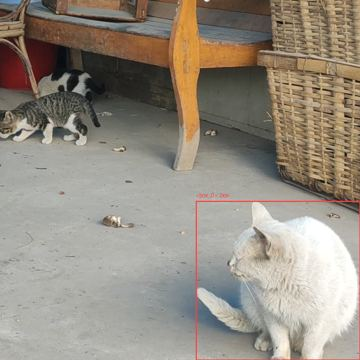
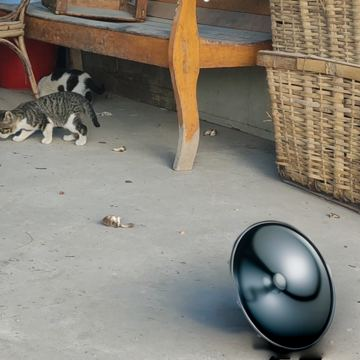
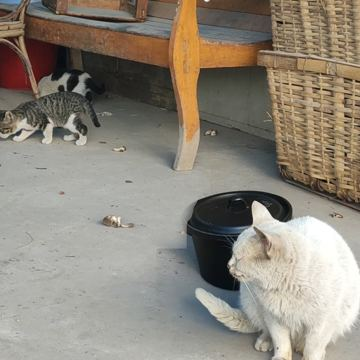


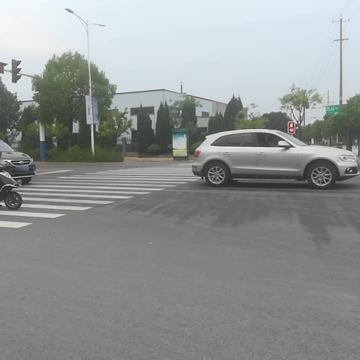
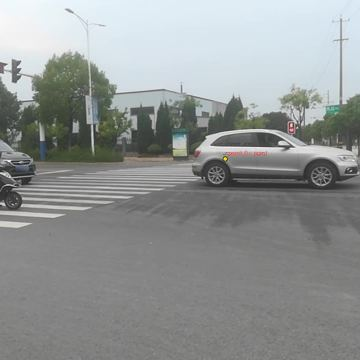
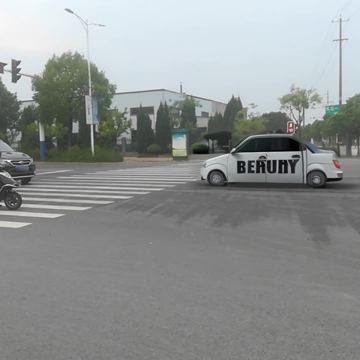
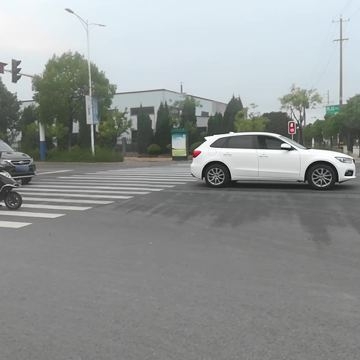


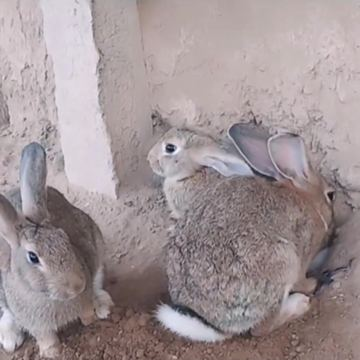
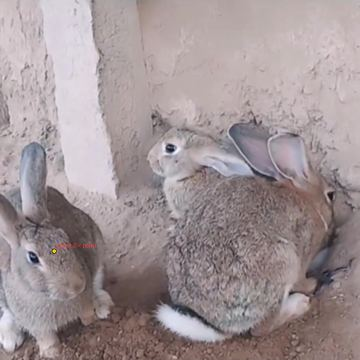
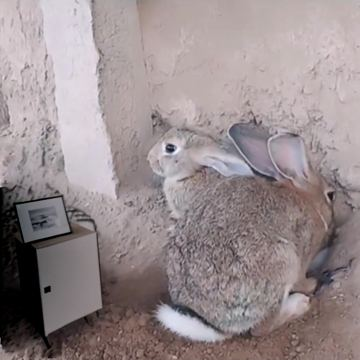
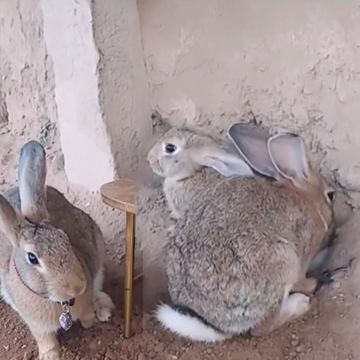


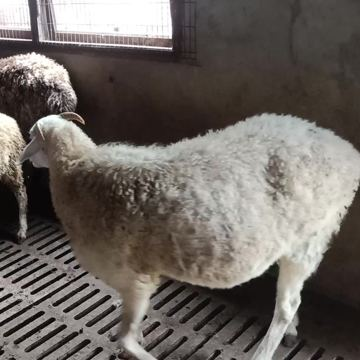
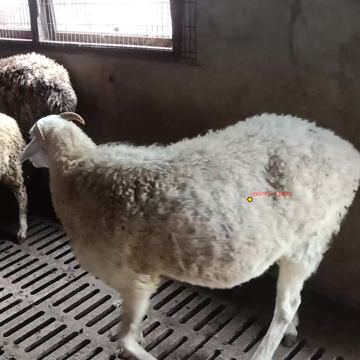
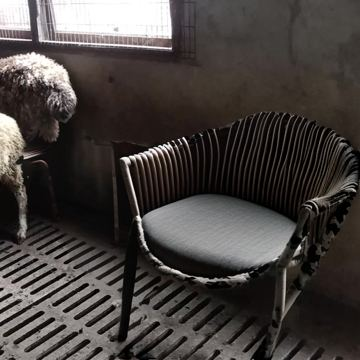
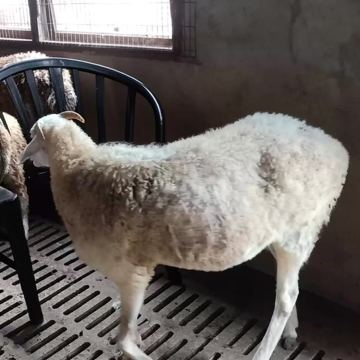


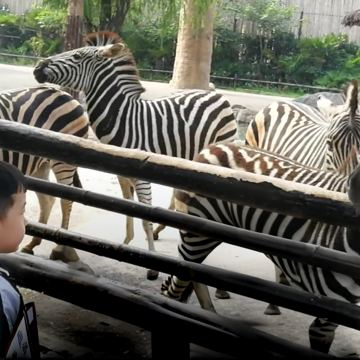
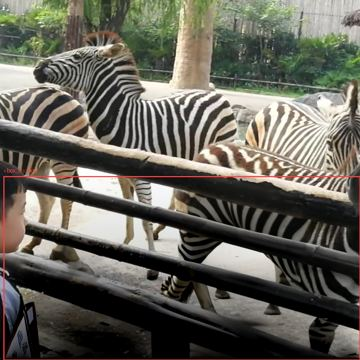
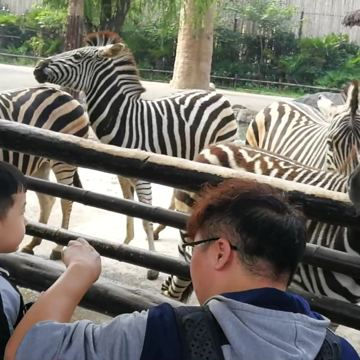
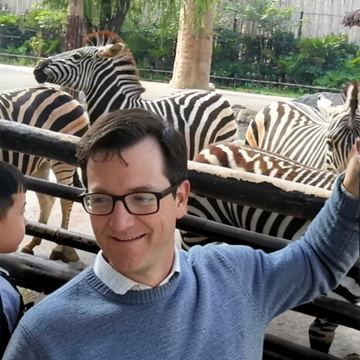


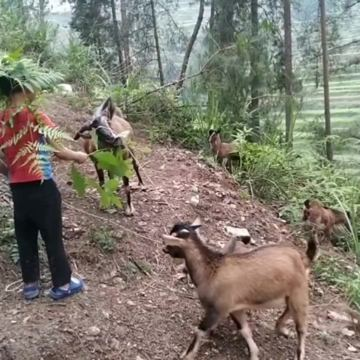
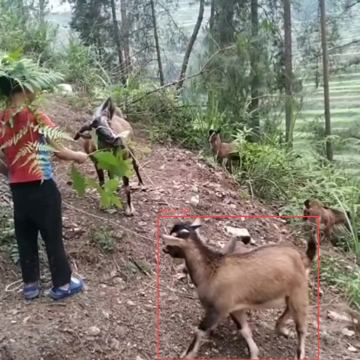
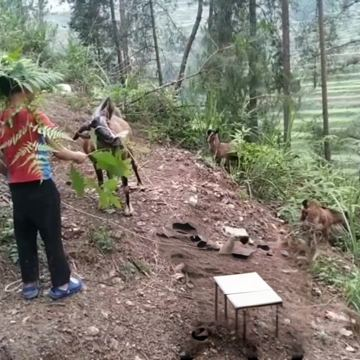
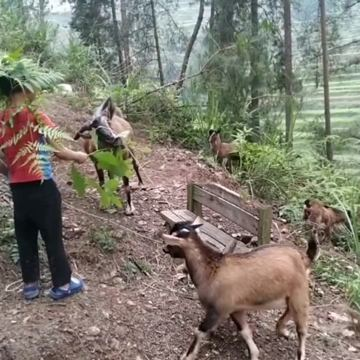


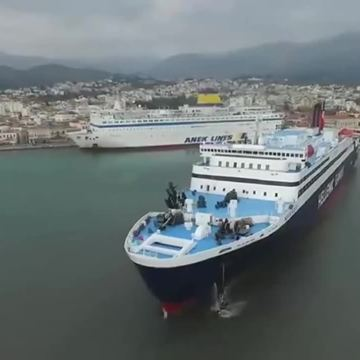
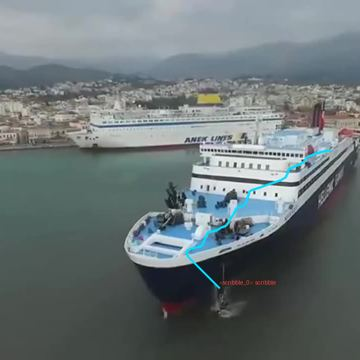
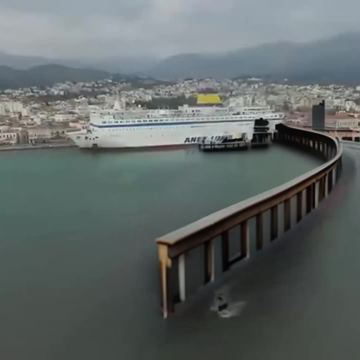
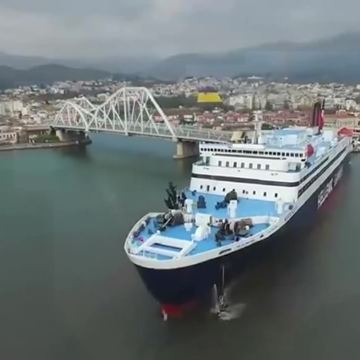


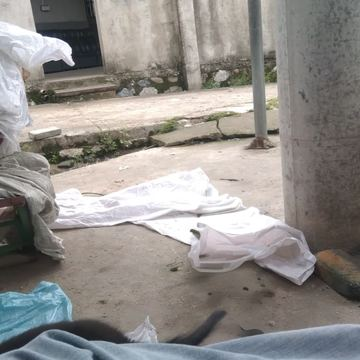
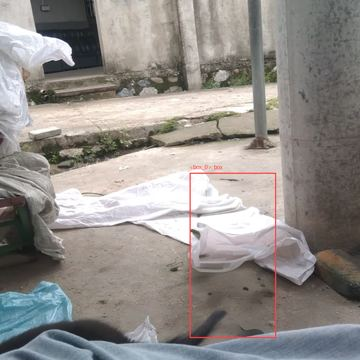
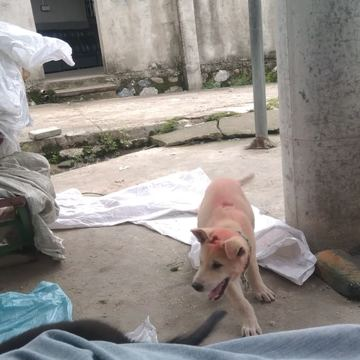
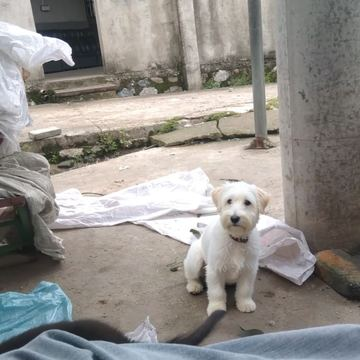

In [2]:
import html
import math

from IPython.display import HTML, display

from evaluation.common import read_jsonl

if not isinstance(TOP_N, int) or isinstance(TOP_N, bool) or TOP_N < 1:
    raise ValueError(f"TOP_N must be a positive integer, got {TOP_N!r}")
if not METRICS_PATH.is_file():
    raise FileNotFoundError(
        f"No saved CompBench metrics at {METRICS_PATH}; run the metrics notebook first."
    )

annotations_by_id = {}
for record in context.records:
    sample_id = record.get("sample_id")
    if not isinstance(sample_id, str) or sample_id in annotations_by_id:
        raise ValueError(f"Missing or duplicate annotation sample_id: {sample_id!r}")
    annotations_by_id[sample_id] = record

results_by_id = {}
if RESULTS_PATH.is_file():
    for result in read_jsonl(RESULTS_PATH):
        sample_id = result.get("sample_id")
        if sample_id is not None:
            results_by_id[str(sample_id)] = result

metric_rows = list(read_jsonl(METRICS_PATH))
if not metric_rows:
    raise ValueError(f"No per-sample metric rows in {METRICS_PATH}")
for row in metric_rows:
    if row.get("prompt_mode") != PROMPT_MODE:
        raise ValueError(
            f"Expected {PROMPT_MODE!r} metrics, got {row.get('prompt_mode')!r} "
            f"for {row.get('sample_id')!r}"
        )
    if row.get("sample_id") not in annotations_by_id:
        raise ValueError(
            f"Metric sample is absent from selected annotations: {row.get('sample_id')!r}"
        )

metric_directions = {
    "SSIM": "ascending",
    "PSNR": "ascending",
    "LPIPS": "descending",
    "LC-T": "ascending",
    "LC-I": "ascending",
}
filtered_rows = [
    row for row in metric_rows
    if TASK_FILTER is None or row.get("task") == TASK_FILTER
]
if not filtered_rows:
    raise ValueError(f"No metric rows match TASK_FILTER={TASK_FILTER!r}")

def _format_cell(value):
    return html.escape(str(value if value is not None else ""))

def display_worst_samples(metric):
    reverse = metric_directions[metric] == "descending"
    candidates = []
    for row in filtered_rows:
        value = row.get(metric)
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f"Invalid {metric} score for {row.get('sample_id')!r}: {value!r}")
        if not math.isfinite(value):
            raise ValueError(f"Non-finite {metric} score for {row.get('sample_id')!r}")
        candidates.append(row)
    worst = sorted(candidates, key=lambda row: row[metric], reverse=reverse)[:TOP_N]
    table_rows = []
    for rank, row in enumerate(worst, 1):
        sample_id = row["sample_id"]
        annotation = annotations_by_id[sample_id]
        result = results_by_id.get(sample_id, {})
        output_path = Path(row.get("output_path", "")).expanduser()
        output_link = (
            f'<a href="{html.escape(output_path.resolve().as_uri(), quote=True)}">output</a>'
            if output_path.is_file()
            else "missing"
        )
        trajectory = result.get("trajectory_text_path")
        trace_link = ""
        if isinstance(trajectory, str) and Path(trajectory).is_file():
            trace_link = (
                f'<a href="{html.escape(Path(trajectory).resolve().as_uri(), quote=True)}">'
                "trace</a>"
            )
        table_rows.append(
            "<tr>"
            f"<td>{rank}</td><td>{row[metric]:.4f}</td>"
            f"<td>{_format_cell(row.get('task'))}</td>"
            f"<td>{_format_cell(sample_id)}</td>"
            f"<td>{_format_cell(annotation.get('original_instruction'))}</td>"
            f"<td>{_format_cell(annotation.get('mixed_instruction'))}</td>"
            f"<td>{output_link} {trace_link}</td>"
            "</tr>"
        )
    headers = ("Rank", metric, "Task", "Sample ID", "Original instruction", "Mixed instruction", "Files")
    header_html = "".join(f"<th>{_format_cell(header)}</th>" for header in headers)
    display(
        HTML(
            f"<h3>Worst {len(worst)} by {metric} ({metric_directions[metric]})</h3>"
            '<table style="border-collapse:collapse;width:100%">'
            f"<thead><tr>{header_html}</tr></thead>"
            f"<tbody>{''.join(table_rows)}</tbody></table>"
        )
    )

from evaluation.compbench_metrics_debug import display_worst_sample_details

for metric_name in metric_directions:
    display_worst_samples(metric_name)
    reverse = metric_directions[metric_name] == "descending"
    ranked_rows = sorted(filtered_rows, key=lambda row: row[metric_name], reverse=reverse)[:TOP_N]
    for rank, row in enumerate(ranked_rows, 1):
        sample_id = row["sample_id"]
        display_worst_sample_details(
            row,
            rank,
            metric_name,
            annotation=annotations_by_id[sample_id],
            result=results_by_id.get(sample_id, {}),
            output_dir=OUTPUT_DIR,
            sample_output_path=row.get("output_path"),
        )

## Replay one sample from its saved trajectory

Set `REPLAY_SAMPLE_ID` in the preparation cell, then run the cells in order. Preparation loads the saved input, prompt values, trajectory, and seed without initializing models. The model-loading cell is resource-intensive and may exhaust memory; run it only when ready. The final cell executes each saved `Act` in order without asking the agent/model to generate a new plan. Model/runtime nondeterminism can prevent pixel-identical output.

In [ ]:
import json
import os
from pathlib import Path

from PIL import Image as PILImage

from evaluation.common import read_jsonl
from evaluation.notebook import load_benchmark, resolve_run_directory

REPLAY_SAMPLE_ID = "multi_object_remove:1dc12eca_00042.png"

replay_prompt_mode = globals().get("PROMPT_MODE", "mixed")
replay_context = load_benchmark("compbench", prompt_mode=replay_prompt_mode)
replay_run_env = f"MMEDIT_COMPBENCH_{replay_prompt_mode.upper()}_RUN"
replay_output_dir = resolve_run_directory(
    replay_context.output_dir, os.environ.get(replay_run_env) or None
)
replay_metrics_path = replay_output_dir / "metrics" / "compbench_metrics.jsonl"
replay_results_path = replay_output_dir / "results" / "results.jsonl"
if not replay_metrics_path.is_file():
    raise FileNotFoundError(f"No saved metrics: {replay_metrics_path}")
replay_annotations = {
    record["sample_id"]: record for record in replay_context.records
}
replay_results = {
    str(result["sample_id"]): result
    for result in read_jsonl(replay_results_path)
    if result.get("sample_id") is not None
}
replay_metrics = list(read_jsonl(replay_metrics_path))
replay_metric = next(
    (row for row in replay_metrics if row.get("sample_id") == REPLAY_SAMPLE_ID), None
)
if replay_metric is None:
    raise KeyError(f"No metric row for sample_id={REPLAY_SAMPLE_ID!r} in {replay_metrics_path}")
replay_result = replay_results.get(REPLAY_SAMPLE_ID)
if replay_result is None:
    raise KeyError(f"No inference result for sample_id={REPLAY_SAMPLE_ID!r} in {replay_results_path}")
replay_annotation = replay_annotations.get(REPLAY_SAMPLE_ID)
if replay_annotation is None:
    raise KeyError(f"No annotation for sample_id={REPLAY_SAMPLE_ID!r}")

metric_output = Path(replay_metric["output_path"]).expanduser()
image_stem = metric_output.name.removesuffix("_output.png")
if not metric_output.is_file():
    metric_output = replay_output_dir / "results" / "images" / f"{image_stem}_output.png"
source_path = replay_output_dir / "results" / "images" / f"{image_stem}_source.png"
trajectory_path = replay_output_dir / "logs" / image_stem / "trajectory.json"
if not source_path.is_file():
    raise FileNotFoundError(f"Saved input image not found: {source_path}")
if not trajectory_path.is_file():
    raise FileNotFoundError(f"Saved trajectory not found: {trajectory_path}")
trajectory = json.loads(trajectory_path.read_text(encoding="utf-8"))
replay_actions = [step["act"] for step in trajectory if isinstance(step, dict) and step.get("act")]
if not replay_actions or not all(isinstance(action, str) for action in replay_actions):
    raise ValueError(f"Trajectory has no replayable Act code: {trajectory_path}")

replay_objects = {"image_0": PILImage.open(source_path).convert("RGB")}
for prompt in replay_result.get("reference_prompts") or []:
    variable = prompt.get("variable")
    if not isinstance(variable, str) or not variable.isidentifier():
        raise ValueError(f"Invalid trajectory input variable: {variable!r}")
    if variable in replay_objects:
        raise ValueError(f"Duplicate trajectory input variable: {variable!r}")
    replay_objects[variable] = prompt["value"]

replay_seed = replay_result.get("random_seed")
if isinstance(replay_seed, bool) or not isinstance(replay_seed, int):
    raise ValueError(f"Invalid saved random_seed: {replay_seed!r}")

print(f"Prepared {len(replay_actions)} saved Act(s) for {REPLAY_SAMPLE_ID}.")

Prepared 1 saved Act(s) for multi_object_remove:1dc12eca_00042.png.


: 

### Load replay models (resource-intensive)

Run this cell only after the preparation cell succeeds. It initializes image-editing models; if the kernel crashes here, it is the model-loading step rather than trajectory execution.

In [ ]:
import framework.tools as framework_tools

if "REPLAY_TOOLS" not in globals():
    replay_model_pool = globals().get("model_pool")
    if replay_model_pool is None:
        from framework.inference import ModelPool

        replay_model_pool = ModelPool()
        model_pool = replay_model_pool
    REPLAY_TOOLS = framework_tools.image_editing_tools(pool=replay_model_pool)
print(f"Loaded {len(REPLAY_TOOLS)} replay tools.")

/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

...

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


### Execute the saved Acts

This runs the stored tool calls with the prepared input and recorded prompt values; it does not call the language model to create a new plan.

In [ ]:
import os
import random

import numpy as np
import torch
from IPython.display import display
from PIL import Image as PILImage

from framework.core import SendMessageTool, local_executor

previous_seed = os.environ.get("RANDOM_SEED")
try:
    os.environ["RANDOM_SEED"] = str(replay_seed)
    random.seed(replay_seed)
    np.random.seed(replay_seed)
    torch.manual_seed(replay_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(replay_seed)

    replay_executor = local_executor(timeout_seconds=300)
    replay_executor.send_tools(
        {tool.name: tool for tool in [*REPLAY_TOOLS, SendMessageTool()]}
    )
    replay_executor.send_variables(replay_objects)
    final_message = None
    for action in replay_actions:
        execution = replay_executor(action)
        if execution.is_final_answer:
            final_message = execution.output
            break
    if not isinstance(final_message, dict):
        raise RuntimeError("Trajectory finished without a send_message result.")
    replay_images = [
        item for item in final_message.get("objects", [])
        if isinstance(item, PILImage.Image)
    ]
    if not replay_images:
        raise RuntimeError("Replayed trajectory did not return an image object.")
    replay_dir = replay_output_dir / "reproductions"
    replay_dir.mkdir(parents=True, exist_ok=True)
    replay_output_path = replay_dir / f"{image_stem}_replayed.png"
    replay_images[0].convert("RGB").save(replay_output_path)

    print("Original output:", metric_output)
    print("Replayed output:", replay_output_path)
    with PILImage.open(metric_output) as original_image:
        display(original_image.convert("RGB"))
    with PILImage.open(replay_output_path) as replayed_image:
        display(replayed_image.convert("RGB"))
finally:
    if previous_seed is None:
        os.environ.pop("RANDOM_SEED", None)
    else:
        os.environ["RANDOM_SEED"] = previous_seed